# Q1D | Train a Linear Regression Model

# 0. Setup

## Imports

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # needed before importing IterativeImputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from Q1.consts import *

from Q1.utils import (
	read_csv_to_df,

	FEATURES,
	PREPROCESSING,
	PIPELINES,
	SCORING
)

from sklearn.linear_model import (
	LinearRegression,
	SGDRegressor,
)

from sklearn.pipeline import FeatureUnion, Pipeline

## Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

X = train_df.drop(columns=TARGET)
y = train_df[TARGET]

## CV Folds

- Every model in this notebook is scored on the same 20 folds: 4-fold CV repeated over the 5 seeds in `FOLD_SEEDS`.
- Validation folds hold complete rows only, so pipelines that drop rows and pipelines that impute are validated on the exact same rows. Incomplete rows only ever join the training side, for pipelines that keep them.
- Every pipeline is cloned and seeded with `SEED` (every `random_state`) by `PIPELINES.evaluate_pipeline`.

In [3]:
FOLDS = PIPELINES.make_folds(X, seeds=FOLD_SEEDS, n_splits=4)

print(f"Folds: {len(FOLDS)}")
print(f"Complete rows (validation): {X.notna().all(axis=1).sum():,}")
print(f"Incomplete rows (training only): {X.isna().any(axis=1).sum():,}")

Folds: 20
Complete rows (validation): 1,374
Incomplete rows (training only): 185


## Data

- `DATA["drop"]`: rows with missing values are dropped once here.
- `DATA["impute"]`: every row, for pipelines with an imputer step.
- Section 1 uses `DATA["drop"]`, except where it compares imputers on `DATA["impute"]`. It picks `BEST_DATA`, and every pipeline from Section 2 on uses `DATA[BEST_DATA]`.

In [4]:
X_drop, y_drop = PREPROCESSING.drop_rows_with_missing_data(X=X.copy(), y=y.copy())

DATA = {"drop": (X_drop, y_drop), "impute": (X, y)}

print(f"Rows kept: {len(X_drop):,} of {len(X):,}")

Rows kept: 1,374 of 1,559


## Helpers

- `variant` clones a base pipeline and changes only the given params.
- `run` shows the pipelines, scores each one on the folds and stores the scores in `RESULTS`.

In [5]:
def variant(base, **changes):
	return clone(base).set_params(**changes)

In [6]:
RESULTS = {}


def run(pipelines: dict, *, data="drop"):
	"""Show the pipelines, evaluate each on DATA[data] with FOLDS, store it in RESULTS, and return just these results."""
	PIPELINES.display_pipeline_grid({(name, data): pipeline for name, pipeline in pipelines.items()})

	X_data, y_data = DATA[data]
	results = {
		name: PIPELINES.evaluate_pipeline(pipeline, X=X_data, y=y_data, folds=FOLDS)
		for name, pipeline in pipelines.items()
	}
	RESULTS.update(results)
	return results

# 1. Feature Set (from Q1C)

- Closed-form `LinearRegression` is exact and has no hyperparameters, so every score change in this section comes from the features alone.
- F0 is the 8 raw attributes. F1 replaces each attribute with the shape Q1C found for it.
- The thresholds are fixed at Q1C's values. Q1C picked them using all training rows, the validation rows of these folds included, so the scores in this section are slightly optimistic.

**Selection rules**

1. F1 is kept only if its verdict against F0 is "candidate" or "significant". Otherwise Q1C's shapes do not help in the multi-feature model, and the rest of the notebook uses the raw features (rules 2 to 4 are then not applied).
2. Ablation, baseline F1, Holm across its 10 rows: each attribute is put back to raw on its own, and Generosity and Negative affect are each also dropped entirely.
3. Generosity and Negative affect are dropped when their dropped row is not "worse".
4. Every other attribute (and those two when not dropped) goes back to raw when its raw row is not "worse". Otherwise its shape is kept. A shape that is not clearly needed does not earn its extra columns.
5. Imputation, baseline the selected feature set on `DATA["drop"]`: the imputer with the lowest mean RMSE among those that are "candidate" or "significant" is used. If none qualifies, rows with missing values stay dropped.

In [7]:
# F0: raw features
LR_BASE = Pipeline([
	('impute', 'passthrough'),
	('transform', 'passthrough'),
	('scale', 'passthrough'),
	('model', LinearRegression()),
])

## F1 | Q1C Shapes

One entry per attribute. `keep_raw=True` keeps the raw column next to the new one.

| entry | attribute | transformer | from Q1C |
|---|---|---|---|
| gdp | Log GDP per capita | `FeatureUnion([("low", HighHinge(t=10.3, keep_raw=True)), ("high", HighHinge(t=10.9))])` | C nested picked (10.3, 10.9) in 15 of 20 folds |
| life_exp | Healthy life expectancy at birth | `HighHinge(t=57.5)` | B, hinge alone |
| social | Social support | `HighHinge(t=0.84, keep_raw=True)` | C fixed |
| freedom | Freedom to make life choices | `HighHinge(t=0.80, keep_raw=True)` | C fixed |
| pos_affect | Positive affect | `Indicator(t=0.749, keep_raw=True)` | D fixed |
| corruption | Perceptions of corruption | `Indicator(t=0.58, keep_raw=True)` | D2 fixed |
| neg_affect | Negative affect | `HighHinge(t=0.20)` | B fixed, hinge alone |
| generosity | Generosity | `Indicator(t=0.087)` | E fixed, indicator alone |

In [8]:
# columns are picked by position, so this also works on an imputer's numpy output,
# and remainder="passthrough" passes any missing-indicator columns through
SHAPES = ColumnTransformer([
	("gdp", FeatureUnion([("low", FEATURES.HighHinge(t=10.3, keep_raw=True)), ("high", FEATURES.HighHinge(t=10.9))]), [X.columns.get_loc("Log GDP per capita")]),
	("life_exp", FEATURES.HighHinge(t=57.5), [X.columns.get_loc("Healthy life expectancy at birth")]),
	("social", FEATURES.HighHinge(t=0.84, keep_raw=True), [X.columns.get_loc("Social support")]),
	("freedom", FEATURES.HighHinge(t=0.80, keep_raw=True), [X.columns.get_loc("Freedom to make life choices")]),
	("pos_affect", FEATURES.Indicator(t=0.749, keep_raw=True), [X.columns.get_loc("Positive affect")]),
	("corruption", FEATURES.Indicator(t=0.58, keep_raw=True), [X.columns.get_loc("Perceptions of corruption")]),
	("neg_affect", FEATURES.HighHinge(t=0.20), [X.columns.get_loc("Negative affect")]),
	("generosity", FEATURES.Indicator(t=0.087), [X.columns.get_loc("Generosity")]),
], remainder="passthrough", verbose_feature_names_out=False)

F1 = variant(LR_BASE, transform=SHAPES)

In [9]:
FEATURE_RESULTS = run({
	"LR | F0 raw": LR_BASE,
	"LR | F1 shapes": F1,
}, data="drop")

FEATURE_TABLE = SCORING.results_df(FEATURE_RESULTS, baseline="LR | F0 raw")
FEATURE_TABLE

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs LR | F0 raw,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
LR | F1 shapes,0.517,0.021,0.395,0.015,0.789,0.017,-0.029,0.006,-5.152,0.0,candidate,20
LR | F0 raw,0.546,0.024,0.422,0.018,0.765,0.020,0.000,NaN,NaN,NaN,baseline,20


In [10]:
SHAPES_HELP = FEATURE_TABLE.loc["LR | F1 shapes", "verdict"] in {"candidate", "significant"}

print(f"SHAPES_HELP: {SHAPES_HELP}")
if not SHAPES_HELP:
	print("Q1C's shapes do not help in the multi-feature model, so the rest of the notebook uses the raw features.")

SHAPES_HELP: True


## Ablation

Each row changes one entry of F1. `raw` puts that attribute back to its raw column, `dropped` removes the attribute. The baseline is F1, and Holm adjusts the p-values for the 10 comparisons.

In [11]:
ENTRIES = ["gdp", "life_exp", "social", "freedom", "pos_affect", "corruption", "neg_affect", "generosity"]
DROP_ENTRIES = ["generosity", "neg_affect"]

ABLATION_CHANGES = {
	f"LR | F1 | {entry} raw": {f"transform__{entry}": "passthrough"}
	for entry in ENTRIES
} | {
	f"LR | F1 | {entry} dropped": {f"transform__{entry}": "drop"}
	for entry in DROP_ENTRIES
}

ABLATION_RESULTS = run(
	{"LR | F1 shapes": F1}
	| {name: variant(F1, **c) for name, c in ABLATION_CHANGES.items()},
	data="drop",
)

ABLATION_TABLE = SCORING.results_df(ABLATION_RESULTS, baseline="LR | F1 shapes", holm=True)
ABLATION_TABLE

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs LR | F1 shapes,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
LR | F1 | generosity dropped,0.516,0.021,0.395,0.015,0.789,0.017,-0.000,0.001,-0.361,0.361,1.0,within noise,20
LR | F1 | corruption raw,0.516,0.021,0.395,0.015,0.789,0.018,-0.000,0.001,-0.443,0.331,1.0,within noise,20
LR | F1 | generosity raw,0.516,0.021,0.396,0.015,0.789,0.017,-0.000,0.001,-0.699,0.246,1.0,within noise,20
LR | F1 | neg_affect dropped,0.516,0.021,0.395,0.015,0.789,0.018,-0.000,0.000,-0.602,0.277,1.0,within noise,20
LR | F1 | freedom raw,0.516,0.021,0.395,0.015,0.789,0.018,-0.000,0.000,-0.977,0.170,1.0,within noise,20
LR | F1 | neg_affect raw,0.516,0.021,0.395,0.015,0.789,0.017,-0.000,0.000,-0.315,0.378,1.0,within noise,20
LR | F1 shapes,0.517,0.021,0.395,0.015,0.789,0.017,0.000,NaN,NaN,NaN,NaN,baseline,20
LR | F1 | pos_affect raw,0.517,0.021,0.396,0.015,0.789,0.018,0.001,0.002,0.332,0.628,1.0,within noise,20
LR | F1 | social raw,0.521,0.022,0.398,0.016,0.786,0.018,0.004,0.002,2.427,0.987,1.0,worse,20


## Selected Feature Set

Rules 3 and 4 applied to the ablation verdicts, giving `F_BEST`. The table after it scores F0, F1 and `F_BEST` together, baseline F0.

In [12]:
FEATURE_CHANGES = {}
for entry in ENTRIES:
	raw_verdict = ABLATION_TABLE.loc[f"LR | F1 | {entry} raw", "verdict"]
	drop_verdict = ABLATION_TABLE.loc[f"LR | F1 | {entry} dropped", "verdict"] if entry in DROP_ENTRIES else None
	if drop_verdict is not None and drop_verdict != "worse":
		FEATURE_CHANGES[f"transform__{entry}"] = "drop"
		decision = "drop"
	elif raw_verdict != "worse":
		FEATURE_CHANGES[f"transform__{entry}"] = "passthrough"
		decision = "raw"
	else:
		decision = "keep shape"
	print(f"{entry}: {decision} (raw row: {raw_verdict}, dropped row: {drop_verdict or 'not tried'})")

F_BEST = variant(F1, **FEATURE_CHANGES) if SHAPES_HELP else LR_BASE

print(f"\nFEATURE_CHANGES: {FEATURE_CHANGES}")
if not SHAPES_HELP:
	print("SHAPES_HELP is False, so F_BEST is LR_BASE (raw features).")

gdp: keep shape (raw row: worse, dropped row: not tried)
life_exp: keep shape (raw row: worse, dropped row: not tried)
social: keep shape (raw row: worse, dropped row: not tried)
freedom: raw (raw row: within noise, dropped row: not tried)
pos_affect: raw (raw row: within noise, dropped row: not tried)
corruption: raw (raw row: within noise, dropped row: not tried)
neg_affect: drop (raw row: within noise, dropped row: within noise)
generosity: drop (raw row: within noise, dropped row: within noise)

FEATURE_CHANGES: {'transform__freedom': 'passthrough', 'transform__pos_affect': 'passthrough', 'transform__corruption': 'passthrough', 'transform__neg_affect': 'drop', 'transform__generosity': 'drop'}


In [13]:
CONFIRM_RESULTS = run({
	"LR | F0 raw": LR_BASE,
	"LR | F1 shapes": F1,
	"LR | best features": F_BEST,
}, data="drop")

SCORING.results_df(CONFIRM_RESULTS, baseline="LR | F0 raw")

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs LR | F0 raw,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
LR | best features,0.516,0.022,0.395,0.016,0.789,0.018,-0.030,0.006,-5.165,0.0,candidate,20
LR | F1 shapes,0.517,0.021,0.395,0.015,0.789,0.017,-0.029,0.006,-5.152,0.0,candidate,20
LR | F0 raw,0.546,0.024,0.422,0.018,0.765,0.020,0.000,NaN,NaN,NaN,baseline,20


## Imputation

- The baseline is `F_BEST` on `DATA["drop"]`. Each imputer becomes the `impute` step of `F_BEST`, run on `DATA["impute"]`, so it also trains on the incomplete rows. The validation rows are the same complete rows either way.
- `median + indicators` adds a 0/1 column for each attribute with missing values in the training fold. These pass through the `transform` step unchanged.
- The KNN imputer is left out. It measures distance in raw units, where Healthy life expectancy (about 50 to 75) dominates, and scaling before it would break the thresholds, which are fixed in raw units.

In [14]:
IMPUTERS = {
	"median": SimpleImputer(strategy="median"),
	"median + indicators": SimpleImputer(strategy="median", add_indicator=True),
	"iterative": IterativeImputer(),
}

IMPUTE_RESULTS = run({"LR | best features | drop rows": F_BEST}, data="drop") | run(
	{f"LR | best features | {name}": variant(F_BEST, impute=imp) for name, imp in IMPUTERS.items()},
	data="impute",
)

IMPUTE_TABLE = SCORING.results_df(IMPUTE_RESULTS, baseline="LR | best features | drop rows")
IMPUTE_TABLE

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs LR | best features | drop rows,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
LR | best features | drop rows,0.516,0.022,0.395,0.016,0.789,0.018,0.000,NaN,NaN,NaN,baseline,20
LR | best features | median,0.516,0.021,0.396,0.015,0.789,0.017,0.000,0.001,0.160,0.563,within noise,20
LR | best features | median + indicators,0.516,0.021,0.396,0.015,0.789,0.017,0.000,0.001,0.210,0.582,within noise,20
LR | best features | iterative,0.517,0.022,0.397,0.016,0.789,0.018,0.001,0.001,0.705,0.755,within noise,20


In [15]:
IMPUTE_WINNERS = [
	name for name in IMPUTERS
	if IMPUTE_TABLE.loc[f"LR | best features | {name}", "verdict"] in {"candidate", "significant"}
]

if IMPUTE_WINNERS:
	best_imputer = min(IMPUTE_WINNERS, key=lambda name: RESULTS[f"LR | best features | {name}"]["rmse"].mean())
	BEST_DATA, BEST_IMPUTE = "impute", IMPUTERS[best_imputer]
else:
	BEST_DATA, BEST_IMPUTE = "drop", 'passthrough'

X_best, y_best = DATA[BEST_DATA]

print(f"BEST_DATA: {BEST_DATA}")
print(f"BEST_IMPUTE: {BEST_IMPUTE}")
print(f"Rows in DATA[BEST_DATA]: {len(X_best):,}")

BEST_DATA: drop
BEST_IMPUTE: passthrough
Rows in DATA[BEST_DATA]: 1,374


## Carried Forward

`SGD_BASE` in Section 2 is built from this section's picks:

- `impute`: `BEST_IMPUTE` (`'passthrough'` when rows with missing values stay dropped).
- `transform`: the `transform` step of `F_BEST` (`'passthrough'` for the raw features).
- `scale`: `StandardScaler`, after the transform, so the thresholds still apply in raw units.
- Every `run` from Section 2 on uses `data=BEST_DATA`, and every fit outside `run` uses `X_best, y_best = DATA[BEST_DATA]`.

# 2. Closed Form vs SGD

- `LinearRegression` solves least squares with `scipy.linalg.lstsq`, which is SVD based. That is the closed-form solution.
- `SGDRegressor` with `penalty=None` fits the same unregularized model with stochastic gradient descent.
- Both use the `impute` and `transform` steps carried forward from Section 1, on `DATA[BEST_DATA]`.
- RMSE is the selection metric (same units as Life Ladder). MAE and R² are shown alongside it.

In [16]:
def clone_step(step):
	"""Clone an estimator step and keep a 'passthrough' string as is (clone does not accept strings)."""
	return step if isinstance(step, str) else clone(step)


SGD_BASE = Pipeline([
	('impute', clone_step(BEST_IMPUTE)),
	('transform', clone_step(F_BEST.named_steps['transform'])),
	('scale', StandardScaler()),
	('model', SGDRegressor(penalty=None)),
])

In [17]:
CLOSED_FORM_RESULTS = run({
	"LR (SVD)": variant(SGD_BASE, model=LinearRegression()),
	"SGD | unscaled": variant(SGD_BASE, scale='passthrough'),
	"SGD | none": SGD_BASE,
}, data=BEST_DATA)

SCORING.results_df(CLOSED_FORM_RESULTS, baseline="LR (SVD)")

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs LR (SVD),Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
LR (SVD),0.516,0.022,0.395,0.016,0.789,0.018,0.000,NaN,NaN,NaN,baseline,20
SGD | none,0.517,0.022,0.396,0.015,0.789,0.018,0.001,0.001,0.957,0.825,within noise,20
SGD | unscaled,0.566,0.029,0.445,0.027,0.746,0.027,0.050,0.015,3.414,0.999,worse,20


`"SGD | unscaled"` is the same SGD model without `StandardScaler`. Gradient descent takes one step size for every feature, so features on very different scales make it unstable. Its row shows why every SGD pipeline below scales its features.

# 3. SGD Regularization

- `l2` = Ridge, `l1` = Lasso, `elasticnet` = Elastic Net (sklearn's default `l1_ratio=0.15`).
- Each penalty is tried with three values of the penalty term `alpha`.
- The baseline is unregularized SGD (`"SGD | none"`). Holm adjusts the p-values for the 9 comparisons.

In [18]:
ALPHAS = [1e-4, 1e-3, 1e-2]
PENALTIES = ["l2", "l1", "elasticnet"]

REG_CHANGES = {
	f"SGD | {p} | alpha={a:g}": dict(model__penalty=p, model__alpha=a)
	for p in PENALTIES
	for a in ALPHAS
}

REG_PIPELINES = {"SGD | none": SGD_BASE} | {name: variant(SGD_BASE, **c) for name, c in REG_CHANGES.items()}

In [19]:
REG_RESULTS = run(REG_PIPELINES, data=BEST_DATA)

SCORING.results_df(REG_RESULTS, baseline="SGD | none", holm=True)

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD | none,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
SGD | l2 | alpha=0.01,0.517,0.022,0.396,0.016,0.789,0.018,-0.000,0.000,-0.415,0.341,1.0,within noise,20
SGD | l2 | alpha=0.001,0.517,0.022,0.396,0.016,0.789,0.018,-0.000,0.000,-0.558,0.292,1.0,within noise,20
SGD | elasticnet | alpha=0.001,0.517,0.022,0.396,0.016,0.789,0.018,-0.000,0.000,-0.153,0.440,1.0,within noise,20
SGD | l2 | alpha=0.0001,0.517,0.022,0.396,0.015,0.789,0.018,-0.000,0.000,-0.572,0.287,1.0,within noise,20
SGD | elasticnet | alpha=0.0001,0.517,0.022,0.396,0.015,0.789,0.018,-0.000,0.000,-0.175,0.431,1.0,within noise,20
SGD | none,0.517,0.022,0.396,0.015,0.789,0.018,0.000,NaN,NaN,NaN,NaN,baseline,20
SGD | l1 | alpha=0.0001,0.517,0.022,0.396,0.015,0.789,0.018,0.000,0.000,0.361,0.639,1.0,within noise,20
SGD | elasticnet | alpha=0.01,0.517,0.022,0.396,0.016,0.789,0.018,0.000,0.000,0.065,0.526,1.0,within noise,20
SGD | l1 | alpha=0.001,0.517,0.022,0.396,0.015,0.789,0.018,0.000,0.000,0.435,0.666,1.0,within noise,20


## Coefficients

Each config fit on all of `DATA[BEST_DATA]`. Coefficients are on the standardized scale, so their sizes are comparable across features. Feature names come from the pipeline's preprocessing steps. This shows the shrinkage from each penalty and any coefficients L1 sets to zero.

In [20]:
REG_FITTED = {name: PIPELINES.seed_pipeline(p).fit(X_best, y_best) for name, p in REG_PIPELINES.items()}

REG_COEFS = pd.DataFrame({
	name: fitted.named_steps['model'].coef_
	for name, fitted in REG_FITTED.items()
}, index=REG_FITTED["SGD | none"][:-1].get_feature_names_out())

REG_COEFS.round(4)

,SGD | none,SGD | l2 | alpha=0.0001,SGD | l2 | alpha=0.001,SGD | l2 | alpha=0.01,SGD | l1 | alpha=0.0001,SGD | l1 | alpha=0.001,SGD | l1 | alpha=0.01,SGD | elasticnet | alpha=0.0001,SGD | elasticnet | alpha=0.001,SGD | elasticnet | alpha=0.01
low__Log GDP per capita,0.2539,0.2539,0.2539,0.2536,0.2539,0.2537,0.2510,0.2539,0.2539,0.2532
low__Log GDP per capita__hinge_10.3,0.1580,0.1579,0.1576,0.1550,0.1576,0.1546,0.1244,0.1579,0.1572,0.1506
high__Log GDP per capita__hinge_10.9,-0.1222,-0.1222,-0.1218,-0.1187,-0.1219,-0.1188,-0.0882,-0.1221,-0.1214,-0.1142
Healthy life expectancy at birth__hinge_57.5,0.3413,0.3412,0.3409,0.3374,0.3413,0.3417,0.3458,0.3413,0.3410,0.3386
Social support,0.1299,0.1299,0.1301,0.1316,0.1299,0.1294,0.1248,0.1299,0.1300,0.1306
Social support__hinge_0.84,0.1196,0.1196,0.1198,0.1208,0.1197,0.1206,0.1289,0.1197,0.1199,0.1220
Freedom to make life choices,0.0455,0.0455,0.0457,0.0476,0.0455,0.0454,0.0439,0.0455,0.0457,0.0470
Positive affect,0.2350,0.2349,0.2347,0.2319,0.2349,0.2347,0.2318,0.2349,0.2347,0.2319
Perceptions of corruption,-0.0500,-0.0500,-0.0501,-0.0506,-0.0500,-0.0496,-0.0463,-0.0500,-0.0500,-0.0500


## Best Regularization

The regularized config with the lowest mean RMSE across the folds.

In [21]:
BEST_REG_NAME = min(REG_CHANGES, key=lambda name: RESULTS[name]["rmse"].mean())
BEST_REG = REG_CHANGES[BEST_REG_NAME]

print(f"BEST_REG_NAME: {BEST_REG_NAME}")
print(f"BEST_REG: {BEST_REG}")

BEST_REG_NAME: SGD | l2 | alpha=0.01
BEST_REG: {'model__penalty': 'l2', 'model__alpha': 0.01}


# 4. Other Hyperparameters (learning rate, scaler)

Every sweep starts from the best regularization config, `"SGD | best reg"`, and changes one hyperparameter at a time.

In [22]:
BEST_REG_PIPELINE = variant(SGD_BASE, **BEST_REG)

## Sweep A | Initial Learning Rate `eta0`

Uses the default `invscaling` schedule. `eta0=0.01` is the sklearn default, so that row matches the baseline.

In [23]:
ETA0S = [1e-3, 1e-2, 1e-1]

ETA0_CHANGES = {
	f"SGD | best reg | eta0={e:g}": BEST_REG | dict(model__eta0=e)
	for e in ETA0S
}

ETA0_RESULTS = run(
	{"SGD | best reg": BEST_REG_PIPELINE}
	| {name: variant(SGD_BASE, **c) for name, c in ETA0_CHANGES.items()},
	data=BEST_DATA,
)

SCORING.results_df(ETA0_RESULTS, baseline="SGD | best reg")

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD | best reg,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
SGD | best reg,0.517,0.022,0.396,0.016,0.789,0.018,0.000,NaN,NaN,NaN,baseline,20
SGD | best reg | eta0=0.01,0.517,0.022,0.396,0.016,0.789,0.018,0.000,0.000,NaN,1.000,within noise,20
SGD | best reg | eta0=0.001,0.522,0.021,0.403,0.015,0.784,0.017,0.006,0.002,2.305,0.984,worse,20
SGD | best reg | eta0=0.1,0.522,0.022,0.400,0.018,0.784,0.018,0.006,0.004,1.615,0.939,worse,20


## Sweep B | Learning Rate Schedule `learning_rate`

Uses the default `eta0=0.01`. `"optimal"` ignores `eta0` and sets its own step size from `alpha`. `"invscaling"` is the sklearn default, so that row matches the baseline.

In [24]:
SCHEDULES = ["constant", "optimal", "invscaling", "adaptive"]

SCHEDULE_CHANGES = {
	f"SGD | best reg | learning_rate={s}": BEST_REG | dict(model__learning_rate=s)
	for s in SCHEDULES
}

SCHEDULE_RESULTS = run(
	{"SGD | best reg": BEST_REG_PIPELINE}
	| {name: variant(SGD_BASE, **c) for name, c in SCHEDULE_CHANGES.items()},
	data=BEST_DATA,
)

SCORING.results_df(SCHEDULE_RESULTS, baseline="SGD | best reg")

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD | best reg,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
SGD | best reg | learning_rate=adaptive,0.516,0.022,0.395,0.016,0.790,0.018,-0.001,0.001,-1.022,0.160,candidate,20
SGD | best reg,0.517,0.022,0.396,0.016,0.789,0.018,0.000,NaN,NaN,NaN,baseline,20
SGD | best reg | learning_rate=invscaling,0.517,0.022,0.396,0.016,0.789,0.018,0.000,0.000,NaN,1.000,within noise,20
SGD | best reg | learning_rate=optimal,0.519,0.022,0.398,0.016,0.787,0.018,0.003,0.003,1.031,0.842,worse,20
SGD | best reg | learning_rate=constant,0.525,0.022,0.402,0.018,0.783,0.018,0.008,0.004,2.070,0.974,worse,20


## Sweep C | Scaler

`MinMaxScaler` in place of `StandardScaler`. It maps each feature to the range 0 to 1 of the training rows instead of to mean 0 and sd 1.

In [25]:
SCALER_CHANGES = {
	"SGD | best reg | MinMaxScaler": BEST_REG | dict(scale=MinMaxScaler()),
}

SCALER_RESULTS = run(
	{"SGD | best reg": BEST_REG_PIPELINE}
	| {name: variant(SGD_BASE, **c) for name, c in SCALER_CHANGES.items()},
	data=BEST_DATA,
)

SCORING.results_df(SCALER_RESULTS, baseline="SGD | best reg")

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD | best reg,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
SGD | best reg,0.517,0.022,0.396,0.016,0.789,0.018,0.000,NaN,NaN,NaN,baseline,20
SGD | best reg | MinMaxScaler,0.548,0.021,0.425,0.018,0.763,0.016,0.032,0.006,4.976,1.0,worse,20


## Best SGD Config

The config with the lowest mean RMSE across `"SGD | best reg"` and all three sweeps.

In [26]:
ALL_CHANGES = {"SGD | best reg": BEST_REG} | ETA0_CHANGES | SCHEDULE_CHANGES | SCALER_CHANGES

BEST_NAME = min(ALL_CHANGES, key=lambda name: RESULTS[name]["rmse"].mean())
BEST_CHANGES = ALL_CHANGES[BEST_NAME]

print(f"BEST_NAME: {BEST_NAME}")
print(f"BEST_CHANGES: {BEST_CHANGES}")

BEST_NAME: SGD | best reg | learning_rate=adaptive
BEST_CHANGES: {'model__penalty': 'l2', 'model__alpha': 0.01, 'model__learning_rate': 'adaptive'}


# 5. Final Model (entire training set)

The best SGD config, seeded and trained on every row of `DATA[BEST_DATA]`.

In [27]:
BEST_PIPELINE = variant(SGD_BASE, **BEST_CHANGES)
FINAL_MODEL = PIPELINES.seed_pipeline(BEST_PIPELINE).fit(X_best, y_best)

In [28]:
final_sgd = FINAL_MODEL.named_steps['model']
default_params = SGDRegressor().get_params()

# params that differ from the SGDRegressor defaults
print("Changed params:")
for key, value in final_sgd.get_params().items():
	if value != default_params[key]:
		print(f"  {key}: {value}")

print(f"\nIntercept: {final_sgd.intercept_[0]:.4f}")
print(f"Training RMSE: {SCORING.root_mean_squared_error(y_best, FINAL_MODEL.predict(X_best)):.4f}")

pd.Series(final_sgd.coef_, index=FINAL_MODEL[:-1].get_feature_names_out(), name="coefficient").round(4)

Changed params:
  alpha: 0.01
  learning_rate: adaptive
  random_state: 42

Intercept: 5.4526
Training RMSE: 0.5124


low__Log GDP per capita                         0.2519
low__Log GDP per capita__hinge_10.3             0.1688
high__Log GDP per capita__hinge_10.9           -0.1216
Healthy life expectancy at birth__hinge_57.5    0.3363
Social support                                  0.1340
Social support__hinge_0.84                      0.1219
Freedom to make life choices                    0.0504
Positive affect                                 0.2315
Perceptions of corruption                      -0.0473
Name: coefficient, dtype: float64

# 6. Training and Validation Loss by Epoch

- The split is fold 0 of `FOLDS.positions_for(X_best)`. Validation is that fold's held-out complete rows, training is the rest of `X_best`.
- The preprocessing steps are fit on the training rows only.
- The model uses `max_iter=1` and `warm_start=True`, so each `fit` call runs one epoch starting from the previous coefficients. Train and validation RMSE are recorded after every epoch.

**Why the selected model's curve can go flat early**

- Each `fit` call restarts SGD's learning rate schedule, and only the coefficients carry over. So the step size never shrinks past what one epoch reaches.
- The seed is the same on every call, so every epoch also visits the rows in the same order.
- With a step size that never shrinks and the same row order every epoch, the coefficients can settle on a fixed point near, not at, the least squares optimum. A normal `fit` runs the schedule across all of its epochs, so it does not have this issue, and the CV scores above are not affected.
- For reference, the closed-form `LinearRegression` fit on the same split shows the optimum, and a second curve with a small constant step size (`eta0=0.0001`) shows the model learning gradually across epochs.

In [29]:
N_EPOCHS = 100

train_pos, val_pos = FOLDS.positions_for(X_best)[0]
X_train, y_train = X_best.iloc[train_pos], y_best.iloc[train_pos]
X_val, y_val = X_best.iloc[val_pos], y_best.iloc[val_pos]

print(f"Train rows: {len(X_train):,} | Validation rows: {len(X_val):,}")

Train rows: 1,030 | Validation rows: 344


In [30]:
def epoch_curve(pipeline, n_epochs=N_EPOCHS):
	"""Train one epoch per fit call (max_iter=1, warm_start=True) and record train and validation RMSE after each."""
	seeded = PIPELINES.seed_pipeline(variant(pipeline, model__max_iter=1, model__warm_start=True))
	preprocess = seeded[:-1].fit(X_train, y_train)
	model = seeded[-1]
	Xt_train, Xt_val = preprocess.transform(X_train), preprocess.transform(X_val)

	train_rmse, val_rmse = [], []
	with warnings.catch_warnings():
		# one epoch per fit call never converges, so silence that warning here only
		warnings.simplefilter("ignore", category=ConvergenceWarning)
		for _ in range(n_epochs):
			model.fit(Xt_train, y_train)
			train_rmse.append(SCORING.root_mean_squared_error(y_train, model.predict(Xt_train)))
			val_rmse.append(SCORING.root_mean_squared_error(y_val, model.predict(Xt_val)))
	return train_rmse, val_rmse

## Selected Model

In [31]:
train_rmse, val_rmse = epoch_curve(BEST_PIPELINE)

print(f"Train RMSE, epochs 1 to 5: {[round(r, 4) for r in train_rmse[:5]]}")
print(f"Validation RMSE, epochs 1 to 5: {[round(r, 4) for r in val_rmse[:5]]}")
print(f"Final epoch train RMSE: {train_rmse[-1]:.4f}")
print(f"Final epoch validation RMSE: {val_rmse[-1]:.4f}")
print(f"Train RMSE change over epochs 10 to 100: {max(train_rmse[9:]) - min(train_rmse[9:]):.6f}")

Train RMSE, epochs 1 to 5: [0.5338, 0.5336, 0.5335, 0.5335, 0.5335]
Validation RMSE, epochs 1 to 5: [0.5381, 0.5397, 0.54, 0.54, 0.54]
Final epoch train RMSE: 0.5335
Final epoch validation RMSE: 0.5400
Train RMSE change over epochs 10 to 100: 0.000000


## Closed-Form Reference

`LinearRegression` fit on the same training rows, scored on the same validation rows. It marks the lowest training RMSE a linear model can reach on this split.

In [32]:
CLOSED_FORM_FOLD0 = variant(SGD_BASE, model=LinearRegression()).fit(X_train, y_train)

cf_train_rmse = SCORING.root_mean_squared_error(y_train, CLOSED_FORM_FOLD0.predict(X_train))
cf_val_rmse = SCORING.root_mean_squared_error(y_val, CLOSED_FORM_FOLD0.predict(X_val))

print(f"Closed-form train RMSE: {cf_train_rmse:.4f}")
print(f"Closed-form validation RMSE: {cf_val_rmse:.4f}")

Closed-form train RMSE: 0.5134
Closed-form validation RMSE: 0.5123


## Small Constant Step Size

The selected config with `learning_rate="constant"` and `eta0=0.0001`. The small step size makes each epoch move the coefficients only a little, so the learning is visible across epochs.

In [33]:
SLOW_PIPELINE = variant(BEST_PIPELINE, model__learning_rate="constant", model__eta0=1e-4)

slow_train_rmse, slow_val_rmse = epoch_curve(SLOW_PIPELINE)

print(f"Train RMSE, epochs 1 to 5: {[round(r, 4) for r in slow_train_rmse[:5]]}")
print(f"Validation RMSE, epochs 1 to 5: {[round(r, 4) for r in slow_val_rmse[:5]]}")
print(f"Final epoch train RMSE: {slow_train_rmse[-1]:.4f}")
print(f"Final epoch validation RMSE: {slow_val_rmse[-1]:.4f}")

Train RMSE, epochs 1 to 5: [4.9811, 4.4823, 4.0423, 3.6502, 3.299]
Validation RMSE, epochs 1 to 5: [4.9938, 4.4817, 4.0346, 3.6388, 3.2859]
Final epoch train RMSE: 0.5135
Final epoch validation RMSE: 0.5119


## Curves

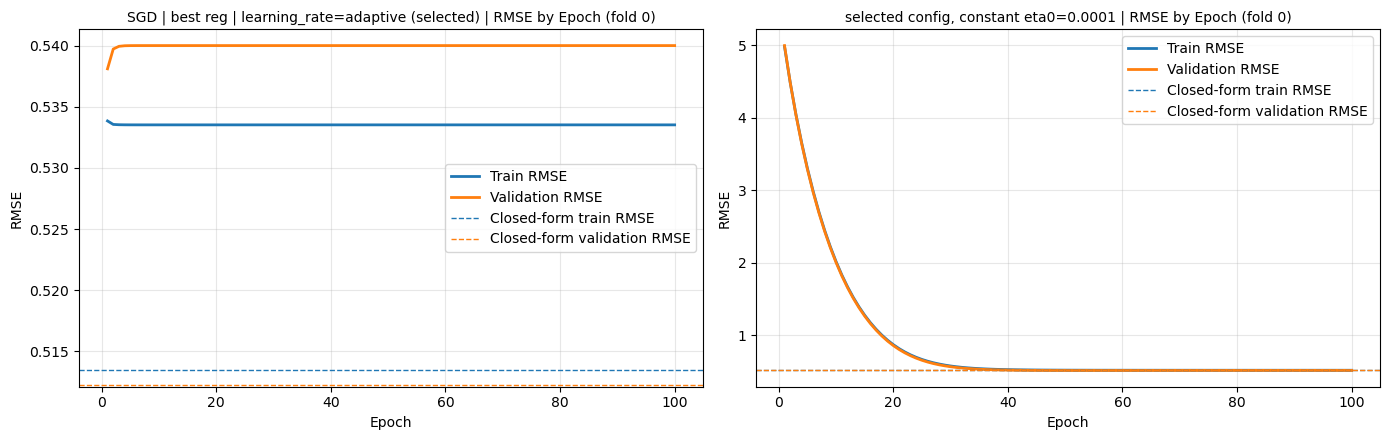

In [34]:
epochs = range(1, N_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
curves = [
	(axes[0], train_rmse, val_rmse, f"{BEST_NAME} (selected)"),
	(axes[1], slow_train_rmse, slow_val_rmse, "selected config, constant eta0=0.0001"),
]
for ax, train, val, title in curves:
	ax.plot(epochs, train, label="Train RMSE", color="C0", linewidth=2)
	ax.plot(epochs, val, label="Validation RMSE", color="C1", linewidth=2)
	ax.axhline(cf_train_rmse, color="C0", linestyle="--", linewidth=1, label="Closed-form train RMSE")
	ax.axhline(cf_val_rmse, color="C1", linestyle="--", linewidth=1, label="Closed-form validation RMSE")
	ax.set_xlabel("Epoch")
	ax.set_ylabel("RMSE")
	ax.set_title(f"{title} | RMSE by Epoch (fold 0)", fontsize=10)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

# 7. Findings

## Feature Set Findings

- **Q1C's shapes help in the multi-feature model.** All eight shapes together (F1) lower RMSE from 0.546 to 0.517 and raise R² from 0.765 to 0.789 (Δrmse -0.029, Δ / SE -5.152, candidate).
- **Three shapes carry the gain.** Reverting any of them to raw is "worse": Healthy life expectancy's hinge (rmse 0.527, Δ / SE 3.795), GDP's two bends (0.522, 3.177) and Social support's raw + hinge (0.521, 2.427).
- **The other five add nothing next to them.** Reverting Freedom, Positive affect or Corruption to raw, or dropping Negative affect or Generosity, is within noise (every Δ / SE between -0.977 and 0.332). Their single-attribute gains in Q1C do not hold once the other attributes are in the model.
- **Selected feature set:** 9 columns, scoring rmse 0.516 (Δrmse -0.030, Δ / SE -5.165 vs raw), the same as F1 with five fewer shapes.
- **Imputation does not help.** Median, median + indicators and iterative imputation are all within noise against dropping rows (Δ / SE 0.160, 0.210 and 0.705), so the 185 incomplete rows stay dropped.

#### Carry forward

- GDP two bends (10.3, 10.9), Healthy life expectancy hinge (57.5), Social support raw + hinge (0.84), raw Freedom, Positive affect and Corruption, no Negative affect or Generosity, rows with missing values dropped.

## Closed Form vs SGD Findings

- On the selected feature set, the closed-form solution (`LR (SVD)`) scores RMSE 0.516 (sd 0.022), MAE 0.395 and R² 0.789.
- Scaled SGD with no penalty (`SGD | none`) reaches the same fit: RMSE 0.517, R² 0.789, Δrmse 0.001 (Δ / SE 0.957), within noise.
- Unscaled SGD is "worse": RMSE 0.566 (Δrmse 0.050, Δ / SE 3.414). Every SGD pipeline below scales its features.

## SGD Regularization Findings

- **RMSE impact is small.** Eight of the nine penalty configs score 0.517, within noise of `SGD | none` (every Δ / SE between -0.572 and 0.435, Holm p 1.0).
- **L1 at alpha=0.01 is the only "worse" config** (rmse 0.518, Δ / SE 1.115). It shrinks GDP's bends the most: hinge_10.3 drops from 0.1580 to 0.1244 and hinge_10.9 from -0.1222 to -0.0882. The ablation in Section 1 showed those bends matter, so shrinking them costs accuracy.
- **Coefficient impact grows with alpha.** At alpha=0.0001 every penalty leaves the coefficients nearly unchanged (GDP 0.2539 in every column).
- **L2 at alpha=0.01** shrinks gently with no zeros: hinge_10.3 0.1580 to 0.1550, Healthy life expectancy hinge 0.3413 to 0.3374, Positive affect 0.2350 to 0.2319.
- **Elastic Net at alpha=0.01** lands between L2 and L1 (hinge_10.3 0.1506, hinge_10.9 -0.1142). No penalty sets a coefficient to zero.
- **Selected:** `l2, alpha=0.01` has the lowest mean RMSE, but its Δ / SE is -0.415, so the choice is within noise.

## Other Hyperparameters Findings

- **`eta0`:** the default 0.01 is best (0.517). Both 0.001 (0.522, Δ / SE 2.305) and 0.1 (0.522, Δ / SE 1.615) are "worse": one step size too small to reach the same fit, the other too large.
- **Schedule:** `adaptive` is the only "candidate" (0.516, Δrmse -0.001, Δ / SE -1.022), the one hyperparameter in Sections 3 and 4 that beats its baseline by more than 1 SE. `optimal` (0.519) and `constant` (0.525) are "worse".
- **Scaler:** `MinMaxScaler` is "worse" than `StandardScaler` (0.548 vs 0.517, Δ / SE 4.976). With the same learning rate settings it scores about the same as raw features with closed-form LR (0.546), losing the feature set's gain.
- Learning rate and scaler choices matter more than the penalty here: they move RMSE by up to 0.032, while the penalties move it by 0.001 at most.

## Final Model Findings

- **Selected config:** the Section 1 feature set, `StandardScaler`, SGD with `penalty=l2`, `alpha=0.01`, `learning_rate=adaptive` (default `eta0=0.01`), `random_state=42`, trained on all 1,374 complete rows.
- **CV RMSE** 0.516 and R² 0.790, matching the closed-form `LR (SVD)` on the same features (0.516, 0.789) and below the raw-feature baseline (0.546).
- **Training RMSE** on the full training set is 0.5124, just below the CV RMSE of 0.516, so the model is not overfitting.
- **Coefficients (standardized):** the Healthy life expectancy hinge is the largest (0.3363), then raw GDP (0.2519) and Positive affect (0.2315). GDP's slope rises past 10.3 (hinge 0.1688) and flattens past 10.9 (hinge -0.1216). Social support adds a steeper slope past 0.84 (hinge 0.1219). Freedom (0.0504) and Corruption (-0.0473) are the smallest.

## Training and Validation Loss by Epoch Findings

- **Selected model (left panel):** train RMSE drops from 0.5338 to 0.5335 by epoch 3, while validation RMSE rises slightly from 0.5381 to 0.5400. Both then stay flat: over epochs 10 to 100 the train RMSE changes by 0.000000.
- **It stalls above the optimum.** The closed-form fit on the same split reaches train 0.5134 and validation 0.5123, below both plateaus. The plateau is the loop's fixed point (see the note at the top of this section), not the selected model's real fit, which scores a CV RMSE of 0.516, the same as `LR (SVD)`.
- **Small constant step size (right panel):** starts at train 4.9811 and validation 4.9938, falls smoothly, and levels off by about epoch 40. At epoch 100 it reaches train 0.5135 and validation 0.5119, on the closed-form lines (0.5134 and 0.5123).
- **No sign of overfitting in the right panel.** Train and validation fall together and stay together. The left panel's small validation rise comes with train RMSE also sitting above the closed-form fit, so it reflects the loop's fixed point, not overfitting.
- Fold 0's closed-form validation RMSE (0.5123) is close to the 20-fold CV mean of 0.516, so this split is representative.